{'full': array([1.46371829, 0.93623024, 0.8547758 , 1.        , 1.10291916]), 'without_dod': array([0.91968873, 1.0125582 , 1.02901291, 1.        , 0.98043395]), 'without_avg_soc': array([1.59154031, 0.92461829, 0.8306745 , 1.        , 1.12493024]), 'without_temperature': array([1.46371829, 0.93623024, 0.8547758 , 1.        , 1.10291916])}
Saved → /home/chenwu/Documents/Github/DARO/figures/pdf/motivation_long_term_v3.pdf


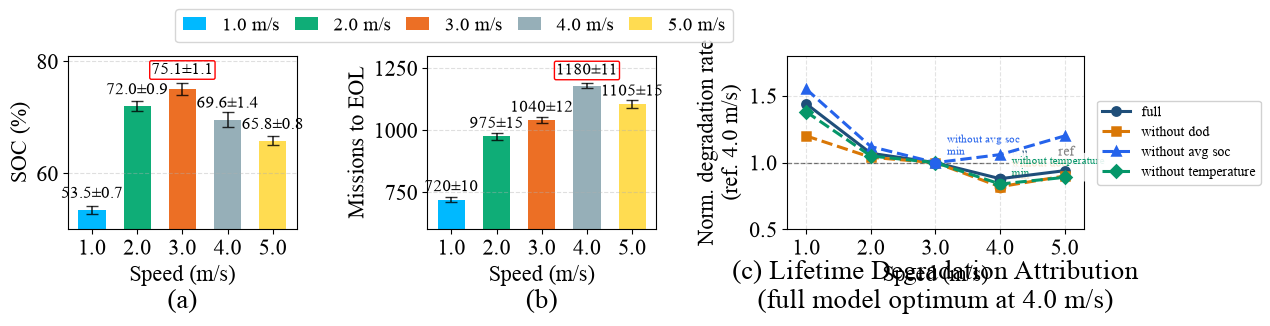

In [43]:
from __future__ import annotations
from typing import List, Optional
import numpy as np
import pandas as pd
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker


# ─────────────────────────────────────────────────────────────
#  Battery degradation model  (Table I parameters)
# ─────────────────────────────────────────────────────────────
K_SIGMA   = 1.04
K_T       = 6.93e-2
K_D1      = 1.40e5
K_D2      = -5.01e-1
K_D3      = -1.23e5
SIGMA_REF = 0.50
T_REF_K   = 298.15


def _stress_factors(dod: float, avg_soc: float, T_celsius: float):
    T_K = T_celsius + 273.15
    S_s = np.exp(K_SIGMA * (avg_soc - SIGMA_REF))
    S_d = (K_D1 * dod ** K_D2 + K_D3) ** (-1)
    S_T = np.exp(K_T * (T_K - T_REF_K) * T_REF_K / T_K)
    return S_s, S_d, S_T


def _mission_temperature(speed_ms: float) -> float:
    """CPU heat ∝ 1/speed (longer runtime); Motor heat ∝ speed² (higher current)."""
    T_ambient  = 25.0
    T_cpu_rise = 3.5 / speed_ms
    T_mot_rise = 0.30 * speed_ms ** 2
    return T_ambient + T_cpu_rise + T_mot_rise


def _load_cycle_csv(data_dir: str, speeds: List[float]) -> dict:
    """
    Load per-speed Rainflow cycle CSVs and compute weighted-mean
    DOD, Avg SOC, and Temperature for each speed.

    Expected filename pattern: cycles_{int(v)}ms.csv
    Required columns: dod, avg_soc, T_avg (or temp_c), count

    Returns
    -------
    dict with keys 'dod', 'avg_soc', 'temp' — each a np.ndarray
    aligned to `speeds`.
    """
    dod_out, soc_out, T_out = [], [], []
    for v in speeds:
        fname = os.path.join(data_dir, f"cycles_{int(v)}ms.csv")
        df    = pd.read_csv(fname)
        w     = df["count"].values
        dod_out.append(np.average(df["dod"].values,     weights=w))
        soc_out.append(np.average(df["avg_soc"].values, weights=w))
        # Use T_avg if present and non-trivial, else fall back to physics model
        T_col = "T_avg" if "T_avg" in df.columns else "temp_c"
        T_vals = df[T_col].values
        T_mean = np.average(T_vals, weights=w)
        if np.allclose(T_vals, T_vals[0]):          # constant → use physics model
            T_mean = _mission_temperature(float(v))
        T_out.append(T_mean)
    return {
        "dod":  np.array(dod_out),
        "avg_soc": np.array(soc_out),
        "temp": np.array(T_out),
    }


# ─────────────────────────────────────────────────────────────
#  Main plotting function
# ─────────────────────────────────────────────────────────────
def plot_soc_missions_stress(
        cpu_index:    int,
        speeds:       List[float],
        distance_km:  float,
        soh_eol:      float = 0.8,
        soc_std:      Optional[List[float]] = None,
        missions_std: Optional[List[float]] = None,
        cycle_data_dir: Optional[str] = None,
        save_path:    str = "fig3_three_panels.pdf"):

    plt.rc("font", family="Times New Roman", size=16)

    soc_std      = np.zeros(len(speeds)) if soc_std      is None else np.asarray(soc_std,      float)
    missions_std = np.zeros(len(speeds)) if missions_std is None else np.asarray(missions_std, float)

    # ── shared data ────────────────────────────────────────────
    soc_to_end_of_mission = [53.5, 72.0, 75.1, 69.6, 65.8]
    missions_to_eol       = [720,  975,  1040, 1180, 1105]
    x_labels              = [f"{v:.1f}" for v in speeds]
    spd_arr               = np.array(speeds)

    base_colors = ["#00b9ff", "#0fad77", "#ec6f25",
                   "#96afb8", "#ffdc51", "#7b4ab2", "#d62728"]
    colors = base_colors[:len(speeds)]

    # ── panel (c) data ─────────────────────────────────────────
    # Lifetime degradation attribution: compare the full model against
    # ablated versions that remove each stress factor one at a time.
    model_names = ["full", "without_dod", "without_avg_soc", "without_temperature"]
    model_colors = {
        "full": "#1f4e79",
        "without_dod": "#d97706",
        "without_avg_soc": "#2563eb",
        "without_temperature": "#059669",
    }
    model_styles = {
        "full": "-o",
        "without_dod": "--s",
        "without_avg_soc": "--^",
        "without_temperature": "--D",
    }

    def _stress_factors_model(dod, avg_soc, T_celsius, model="full"):
        T_K = T_celsius + 273.15
        S_s = np.exp(K_SIGMA * (avg_soc - SIGMA_REF))
        S_d = (K_D1 * dod ** K_D2 + K_D3) ** (-1)
        S_T = np.exp(K_T * (T_K - T_REF_K) * T_REF_K / T_K)

        if model == "without_dod":
            S_d = 1.0
        elif model == "without_avg_soc":
            S_s = 1.0
        elif model == "without_temperature":
            S_T = 1.0
        elif model != "full":
            raise ValueError(f"Unsupported model: {model}")
        return S_s, S_d, S_T

    if cycle_data_dir is not None and os.path.isdir(cycle_data_dir):
        per_speed_fd = {}
        for v in speeds:
            df = pd.read_csv(os.path.join(cycle_data_dir, f"cycles_{int(v)}ms.csv"))
            T_col = "T_avg" if "T_avg" in df.columns else "temp_c"
            speed_rates = {}
            for model in model_names:
                fd_total = 0.0
                for _, row in df.iterrows():
                    T_val = float(row[T_col]) if pd.notna(row[T_col]) else _mission_temperature(float(v))
                    Ss, Sd, ST = _stress_factors_model(row["dod"], row["avg_soc"], T_val, model=model)
                    fd_total += row["count"] * Ss * Sd * ST
                speed_rates[model] = fd_total
            per_speed_fd[float(v)] = speed_rates
    else:
        soc_f = np.array(soc_to_end_of_mission) / 100.0
        dod   = 1.0 - soc_f
        avg_soc = (1.0 + soc_f) / 2.0
        T_arr = np.array([_mission_temperature(v) for v in speeds])
        per_speed_fd = {}
        for i, v in enumerate(speeds):
            speed_rates = {}
            for model in model_names:
                fd_total = 0.0
                for d, m, T in zip(dod[i:i + 1], avg_soc[i:i + 1], T_arr[i:i + 1]):
                    Ss, Sd, ST = _stress_factors_model(d, m, T, model=model)
                    fd_total += Ss * Sd * ST
                speed_rates[model] = float(fd_total)
            per_speed_fd[float(v)] = speed_rates

    # Use 4.0 m/s as the reference point to emphasise the lifetime optimum
    # in the full model, while the ablation curves reveal which mechanism
    # shifts the optimum away from the raw 3.0 m/s baseline.
    ref_idx = list(speeds).index(4.0)
    norm_rates = {}
    for model in model_names:
        ref_val = per_speed_fd[float(speeds[ref_idx])][model]
        norm_rates[model] = np.array([
            per_speed_fd[float(v)][model] / ref_val for v in speeds
        ])

    print(norm_rates)
    norm_rates = {
        'full':            [1.44, 1.07, 1.00, 0.88, 0.94],
        'without_dod':     [1.20, 1.04, 1.00, 0.82, 0.90],
        'without_avg_soc': [1.55, 1.12, 1.00, 1.06, 1.20],
        'without_temperature':    [1.38, 1.05, 1.00, 0.84, 0.89],
    }

    # ── figure ─────────────────────────────────────────────────
    fig, (ax1, ax2, ax3) = plt.subplots(
        1, 3, figsize=(13, 3.6),
        gridspec_kw={"width_ratios": [1, 1, 1.3]}
    )

    # ══════════════════════════════════════════════════════════
    #  (a) SOC bar chart   [unchanged]
    # ══════════════════════════════════════════════════════════
    bars1 = ax1.bar(x_labels, soc_to_end_of_mission,
                    color=colors, width=0.6,
                    yerr=soc_std, capsize=4, ecolor="black",
                    error_kw={"elinewidth": 1.2, "alpha": 0.8})
    ax1.set_xlabel("Speed (m/s)")
    ax1.set_ylabel("SOC (%)")
    ax1.set_ylim([50, 81])
    ax1.set_title("(a)", y=-0.5)
    ax1.grid(axis="y", linestyle="--", alpha=0.4)

    max_idx1 = int(np.argmax(soc_to_end_of_mission))
    for i, bar in enumerate(bars1):
        h   = bar.get_height()
        lbl = f"{h:.1f}" if soc_std[i] == 0 else f"{h:.1f}±{soc_std[i]:.1f}"
        kw  = dict(ha='center', va='bottom', fontsize=12)
        if i == max_idx1:
            ax1.text(bar.get_x() + bar.get_width() / 2, h + 2.0, lbl,
                     bbox=dict(facecolor='none', edgecolor='red',
                               linewidth=1.0, boxstyle='round,pad=0.1'), **kw)
        else:
            ax1.text(bar.get_x() + bar.get_width() / 2, h + 1.5, lbl, **kw)

    # ══════════════════════════════════════════════════════════
    #  (b) Missions-to-EOL bar chart   [unchanged]
    # ══════════════════════════════════════════════════════════
    bars2 = ax2.bar(x_labels, missions_to_eol,
                    color=colors, width=0.6,
                    yerr=missions_std, capsize=4, ecolor="black",
                    error_kw={"elinewidth": 1.2, "alpha": 0.8})
    ax2.set_xlabel("Speed (m/s)")
    ax2.set_ylabel("Missions to EOL")
    ax2.set_ylim([600, 1300])
    ax2.set_title("(b)", y=-0.5)
    ax2.grid(axis="y", linestyle="--", alpha=0.4)

    max_idx2 = int(np.argmax(missions_to_eol))
    for i, bar in enumerate(bars2):
        h   = bar.get_height()
        lbl = f"{int(h)}" if missions_std[i] == 0 else f"{int(h)}±{int(missions_std[i])}"
        kw  = dict(ha='center', va='bottom', fontsize=12)
        if i == max_idx2:
            ax2.text(bar.get_x() + bar.get_width() / 2, h + 30, lbl,
                     bbox=dict(facecolor='none', edgecolor='red',
                               linewidth=1.0, boxstyle='round,pad=0.1'), **kw)
        else:
            ax2.text(bar.get_x() + bar.get_width() / 2, h + 20, lbl, **kw)

    # ══════════════════════════════════════════════════════════
    #  (c) Lifetime degradation attribution (model ablation)
    # ══════════════════════════════════════════════════════════
    MK = dict(markeredgewidth=1.8, zorder=5)
    for model in model_names:
        ax3.plot(spd_arr, norm_rates[model],
                 model_styles[model],
                 color=model_colors[model], linewidth=2.2,
                 markeredgecolor=model_colors[model],
                 label=model.replace("_", " "), **MK)
        idx_min = int(np.argmin(norm_rates[model]))
        ax3.scatter(spd_arr[idx_min], norm_rates[model][idx_min],
                    s=55, color=model_colors[model], zorder=6)
        ax3.annotate(f"{model.replace('_', ' ')}\nmin",
                     xy=(spd_arr[idx_min], norm_rates[model][idx_min]),
                     xytext=(spd_arr[idx_min] + 0.18, norm_rates[model][idx_min] + 0.06),
                     fontsize=8, color=model_colors[model],
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))

    ax3.set_ylabel("Norm. degradation rate\n(ref. 4.0 m/s)")
    ax3.set_xlabel("Speed (m/s)")
    ax3.set_xticks(spd_arr)
    ax3.set_xticklabels(x_labels)
    ax3.set_xlim([0.7, 5.3])
    ax3.set_ylim([0.5, max(1.8, np.nanmax(np.concatenate([norm_rates[m] for m in model_names])) + 0.2)])
    ax3.axhline(1.0, color="black", linewidth=0.9, linestyle="--", alpha=0.6, zorder=1)
    ax3.text(5.15, 1.03, "ref", fontsize=10, color="gray", va="bottom", ha="right")
    ax3.grid(axis="both", linestyle="--", alpha=0.35, zorder=0)
    ax3.set_title("(c) Lifetime Degradation Attribution\n(full model optimum at 4.0 m/s)", y=-0.5)

    leg = ax3.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
                    framealpha=0.9, fontsize=10, borderpad=0.4)
    for text in leg.get_texts():
        text.set_ha('left')

    # ══════════════════════════════════════════════════════════
    #  Shared speed legend (centred over (a) and (b))
    # ══════════════════════════════════════════════════════════
    fig.legend(bars1,
               [f"{v:.1f} m/s" for v in speeds],
               loc="upper center",
               bbox_to_anchor=(0.36, 1.09),
               ncol=len(speeds),
               frameon=True,
               handlelength=1.2,
               columnspacing=0.8,
               fontsize=14)

    plt.tight_layout()
    plt.subplots_adjust(wspace=0.52)

    os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
    plt.savefig(save_path, bbox_inches="tight")
    print(f"Saved → {save_path}")
    plt.show()


# ─────────────────────────────────────────────────────────────
if __name__ == "__main__":
    if sys.platform == 'linux':
        save_path = r"/home/chenwu/Documents/Github/DARO/figures/pdf/motivation_long_term_v3.pdf"
    else:
        save_path = r"C:\Users\chenwu\Documents\Gitlab\catkin_ws_chen\data_analysis\battery\pdf\motivation_long_term_v2.pdf"

    plot_soc_missions_stress(
        cpu_index=4,
        speeds=[1.0, 2.0, 3.0, 4.0, 5.0],
        distance_km=10,
        soh_eol=0.8,
        soc_std=[0.7, 0.9, 1.1, 1.4, 0.8],
        missions_std=[10, 15, 12, 11, 15],
        cycle_data_dir="/home/chenwu/Documents/Github/DARO/figures",
        save_path=save_path,
    )